# Sistem Basis Data Perpustakaan dengan SQLite

Tugas Google Colab: membuat database, mengisi data, menjalankan JOIN dan GROUP BY, lalu eksplorasi data menggunakan pandas dan matplotlib.

**Catatan:** seluruh data pada notebook ini merupakan data simulasi.

## 1. Import library

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("Library berhasil diimpor.")

Library berhasil diimpor.


## 2. Membuat database dan tiga tabel SQLite

In [3]:
conn = sqlite3.connect("perpustakaan.db")
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

cursor.executescript("""
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS anggota;
DROP TABLE IF EXISTS buku;

CREATE TABLE buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);

CREATE TABLE anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT NOT NULL UNIQUE
);

CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam TEXT NOT NULL,
    tgl_kembali TEXT,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")
conn.commit()
print("Database dan tiga tabel berhasil dibuat.")

Database dan tiga tabel berhasil dibuat.


## 3. Menambahkan 5 data buku dan 3 data anggota

In [7]:
data_buku = [
    ("Laskar Pelangi", "Andrea Hirata", 2005),
    ("Bumi", "Tere Liye", 2014),
    ("Negeri 5 Menara", "Ahmad Fuadi", 2009),
    ("Pulang", "Tere Liye", 2015),
    ("Filosofi Teras", "Henry Manampiring", 2018)
]

data_anggota = [
    ("Andi Saputra", "andi@gmail.com"),
    ("Siti Rahma", "siti@gmail.com"),
    ("Budi Santoso", "budi@gmail.com")
]

cursor.executemany(
    "INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?)",
    data_buku
)
cursor.executemany(
    "INSERT INTO anggota (nama, email) VALUES (?, ?)",
    data_anggota
)
conn.commit()

print("Tabel buku:")
display(pd.read_sql_query("SELECT * FROM buku", conn))
print("Tabel anggota:")
display(pd.read_sql_query("SELECT * FROM anggota", conn))

Tabel buku:


,id,judul,penulis,tahun
0,1,Laskar Pelangi,Andrea Hirata,2005
1,2,Bumi,Tere Liye,2014
2,3,Negeri 5 Menara,Ahmad Fuadi,2009
3,4,Pulang,Tere Liye,2015
4,5,Filosofi Teras,Henry Manampiring,2018


Tabel anggota:


,id,nama,email
0,1,Andi Saputra,andi@gmail.com
1,2,Siti Rahma,siti@gmail.com
2,3,Budi Santoso,budi@gmail.com


## 4. Menambahkan 4 transaksi peminjaman
Satu transaksi belum dikembalikan sehingga `tgl_kembali` bernilai `NULL`.

In [8]:
data_peminjaman = [
    (1, 1, "2026-11-01", "2026-11-07"),
    (2, 2, "2026-11-03", "2026-11-10"),
    (1, 3, "2026-11-12", None),  # Belum dikembalikan
    (3, 4, "2026-11-15", "2026-11-20")
]

cursor.executemany(
    """
    INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali)
    VALUES (?, ?, ?, ?)
    """,
    data_peminjaman
)
conn.commit()
display(pd.read_sql_query("SELECT * FROM peminjaman", conn))

,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2026-11-01,2026-11-07
1,2,2,2,2026-11-03,2026-11-10
2,3,1,3,2026-11-12,None
3,4,3,4,2026-11-15,2026-11-20


## 5. Menampilkan daftar peminjaman lengkap menggunakan JOIN

In [9]:
query_join = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali,
    CASE WHEN p.tgl_kembali IS NULL
         THEN 'Belum dikembalikan'
         ELSE 'Sudah dikembalikan'
    END AS status
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
ORDER BY p.id;
"""

df_peminjaman = pd.read_sql_query(query_join, conn)
display(df_peminjaman)

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,status
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07,Sudah dikembalikan
1,2,Siti Rahma,Bumi,2026-11-03,2026-11-10,Sudah dikembalikan
2,3,Andi Saputra,Negeri 5 Menara,2026-11-12,None,Belum dikembalikan
3,4,Budi Santoso,Pulang,2026-11-15,2026-11-20,Sudah dikembalikan


## 6. Menghitung jumlah peminjaman per anggota dengan GROUP BY

In [10]:
query_group = """
SELECT
    a.id,
    a.nama AS nama_anggota,
    COUNT(p.id) AS jumlah_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY jumlah_buku_dipinjam DESC;
"""

df_ringkasan = pd.read_sql_query(query_group, conn)
display(df_ringkasan)

,id,nama_anggota,jumlah_buku_dipinjam
0,1,Andi Saputra,2
1,2,Siti Rahma,1
2,3,Budi Santoso,1


## 7. Eksplorasi data dengan pandas
Durasi dihitung untuk transaksi yang sudah dikembalikan. Jika tanggal kembali `NULL`, durasi dibiarkan kosong.

In [12]:
df_peminjaman["tgl_pinjam"] = pd.to_datetime(df_peminjaman["tgl_pinjam"])
df_peminjaman["tgl_kembali"] = pd.to_datetime(df_peminjaman["tgl_kembali"])

df_peminjaman["durasi_hari"] = (
    df_peminjaman["tgl_kembali"] - df_peminjaman["tgl_pinjam"]
).dt.days

display(df_peminjaman)
print("Jumlah transaksi:", len(df_peminjaman))
print("Sudah dikembalikan:", df_peminjaman["tgl_kembali"].notna().sum())
print("Belum dikembalikan:", df_peminjaman["tgl_kembali"].isna().sum())
print("Rata-rata durasi (transaksi yang sudah kembali):",
      round(df_peminjaman["durasi_hari"].mean(), 2), "hari")

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,status,durasi_hari
0,1,Andi Saputra,Laskar Pelangi,2026-11-01,2026-11-07,Sudah dikembalikan,6.0
1,2,Siti Rahma,Bumi,2026-11-03,2026-11-10,Sudah dikembalikan,7.0
2,3,Andi Saputra,Negeri 5 Menara,2026-11-12,NaT,Belum dikembalikan,NaN
3,4,Budi Santoso,Pulang,2026-11-15,2026-11-20,Sudah dikembalikan,5.0


Jumlah transaksi: 4
Sudah dikembalikan: 3
Belum dikembalikan: 1
Rata-rata durasi (transaksi yang sudah kembali): 6.0 hari


## 8. Diagram batang jumlah peminjaman per anggota

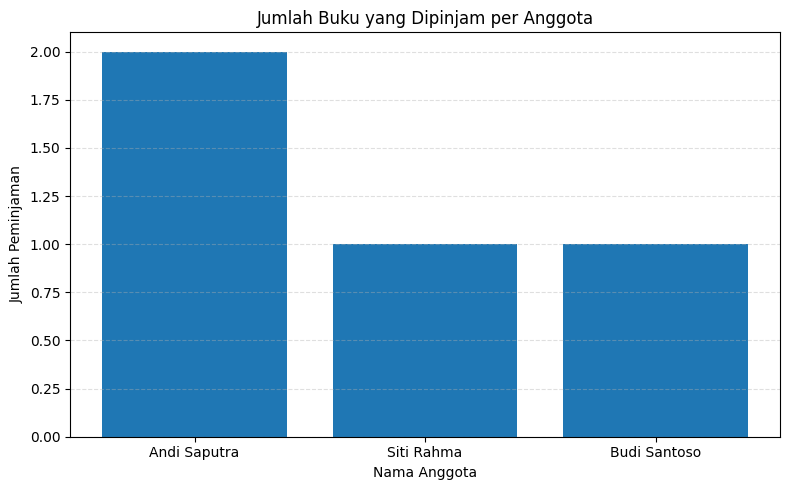

In [13]:
plt.figure(figsize=(8, 5))
plt.bar(df_ringkasan["nama_anggota"], df_ringkasan["jumlah_buku_dipinjam"])
plt.title("Jumlah Buku yang Dipinjam per Anggota")
plt.xlabel("Nama Anggota")
plt.ylabel("Jumlah Peminjaman")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 9. Histogram durasi peminjaman

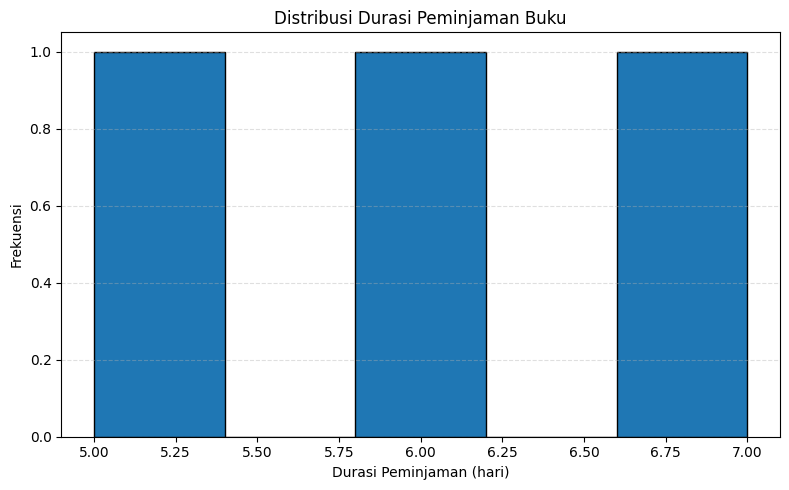

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# Pastikan kolom bertipe numerik, nilai yang gagal dikonversi jadi NaN lalu dibuang
durasi_valid = pd.to_numeric(df_peminjaman["durasi_hari"], errors="coerce").dropna()

# Opsional: buang durasi negatif (biasanya akibat tanggal kembali < tanggal pinjam)
durasi_valid = durasi_valid[durasi_valid >= 0]

plt.figure(figsize=(8, 5))
plt.hist(durasi_valid, bins=5, edgecolor="black")
plt.title("Distribusi Durasi Peminjaman Buku")
plt.xlabel("Durasi Peminjaman (hari)")
plt.ylabel("Frekuensi")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 10. Kesimpulan

1. Database perpustakaan berhasil dibuat menggunakan SQLite dengan tiga tabel yang saling berhubungan.
2. Tabel buku berisi 5 data, tabel anggota 3 data, dan tabel peminjaman 4 transaksi.
3. JOIN menampilkan nama anggota dan judul buku dalam satu tabel.
4. GROUP BY dan COUNT menghitung jumlah transaksi peminjaman setiap anggota.
5. Pandas digunakan untuk menghitung durasi peminjaman.
6. Diagram batang menunjukkan jumlah peminjaman per anggota dan histogram menunjukkan distribusi durasi.

Transaksi yang belum dikembalikan tidak dihitung durasinya karena tanggal kembali masih `NULL`.